# 1. Imports


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 2. Path config


In [3]:
ROOT = Path.cwd().parent.parent.parent
DATA_DIR = ROOT / "data"
print(ROOT)
print(DATA_DIR)

/home/samuel/projects/machine-learning-from-scratch
/home/samuel/projects/machine-learning-from-scratch/data


# 3. Load data


In [4]:
df = pd.read_csv(DATA_DIR / "API_NY.GDP.PCAP.CD_DS2_en_csv_v2_1529.csv")
# gdp_df.rename(columns={"Entity": "country_name", "Year": "year", "GDP per capita": "GDP_per_capita"}, inplace=True)

In [5]:
# Remove unnecessary columns
df = df.drop(columns=["Unnamed: 70"], errors="ignore")

# Remove metadata columns that are not needed
df = df.drop(columns=["Indicator Name", "Indicator Code"])

# Rename columns
df = df.rename(columns={"Country Name": "country", "Country Code": "country_code"})

# Remove rows without country information
df = df.dropna(subset=["country", "country_code"])

# Remove duplicate countries
df = df.drop_duplicates(subset=["country_code"])

In [6]:
df = df.melt(
    id_vars=["country", "country_code"], var_name="year", value_name="gdp_per_capita"
)

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["gdp_per_capita"] = pd.to_numeric(df["gdp_per_capita"], errors="coerce")

df = df.dropna(subset=["year", "gdp_per_capita"])

df["year"] = df["year"].astype(int)

df = df.sort_values(["country", "year"]).reset_index(drop=True)

In [7]:
df.head()

,country,country_code,year,gdp_per_capita
0,Afghanistan,AFG,2000,174.930991
1,Afghanistan,AFG,2001,138.706822
2,Afghanistan,AFG,2002,178.954088
3,Afghanistan,AFG,2003,198.871116
4,Afghanistan,AFG,2004,221.763654


# 4. Data exploration by country


In [8]:
def df_filtered_by_country(df, country):
    return df[df["country"] == country]

In [9]:
df_brazil = df_filtered_by_country(df, "Brazil")
df_portugal = df_filtered_by_country(df, "Portugal")

df_brazil.head()

,country,country_code,year,gdp_per_capita
1591,Brazil,BRA,1960,235.266010
1592,Brazil,BRA,1961,231.564063
1593,Brazil,BRA,1962,250.200573
1594,Brazil,BRA,1963,294.169619
1595,Brazil,BRA,1964,257.259727


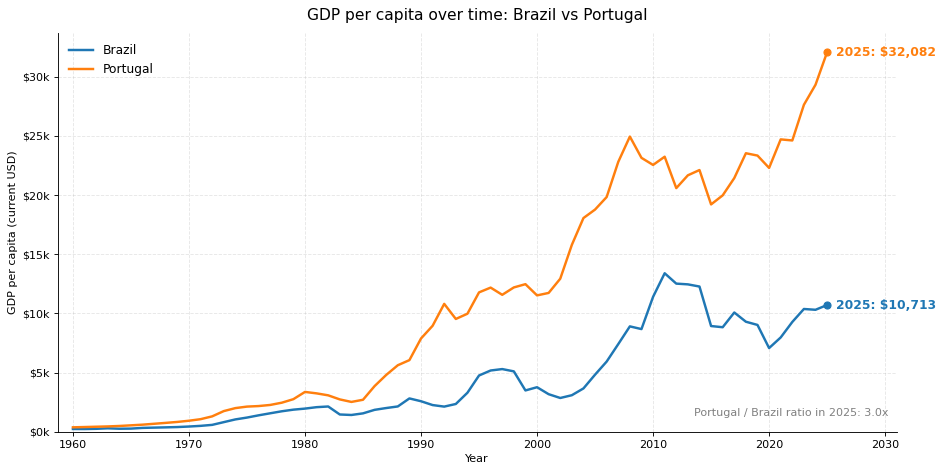

In [46]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


def plot_gdp_comparison(
    df_a, df_b, label_a="Brazil", label_b="Portugal", save_path=None
):
    colors = {label_a: "#1f77b4", label_b: "#ff7f0e"}

    fig, ax = plt.subplots(figsize=(12, 6), dpi=80)

    for df, label in [(df_a, label_a), (df_b, label_b)]:
        ax.plot(
            df["year"],
            df["gdp_per_capita"],
            label=label,
            color=colors[label],
            linewidth=2.2,
        )
        # Marker + annotation at the last data point
        x_last = df["year"].iloc[-1]
        y_last = df["gdp_per_capita"].iloc[-1]
        ax.scatter(x_last, y_last, color=colors[label], s=40, zorder=3)
        ax.annotate(
            f"{x_last}: ${y_last:,.0f}",
            xy=(x_last, y_last),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            fontsize=11,
            fontweight="bold",
            color=colors[label],
        )

    # Ratio between the two countries in the latest year
    ratio = df_b["gdp_per_capita"].iloc[-1] / df_a["gdp_per_capita"].iloc[-1]
    ax.text(
        0.99,
        0.04,
        f"{label_b} / {label_a} ratio in {df_a['year'].iloc[-1]}: {ratio:.1f}x",
        transform=ax.transAxes,
        ha="right",
        fontsize=10,
        color="gray",
    )

    # Axes formatting
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k"))
    ax.set_xlabel("Year")
    ax.set_ylabel("GDP per capita (current USD)")
    ax.set_title("GDP per capita over time: Brazil vs Portugal", fontsize=14, pad=12)

    ax.set_ylim(bottom=0)
    ax.margins(x=0.02)
    ax.set_xlim(right=df_a["year"].max() + 6)  # room for end labels

    ax.grid(True, alpha=0.3, linestyle="--")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=11)

    fig.tight_layout()

    if save_path is not None:
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight", facecolor="white")

    return fig, ax


save_path = (
    ROOT / "outputs_results/03_linear_regression_timeseries_forecast/gdp_comparison.png"
)
fig, ax = plot_gdp_comparison(df_brazil, df_portugal, save_path=save_path)
plt.show()

## Time Series Forecasting Workflow

<img src="https://drive.google.com/uc?export=view&id=1Q81ViU2xgqtRmDp6tjNQvDgDpbzUUZ3R"
     alt="Time Series Forecasting Workflow"
     width="700">

# 5. Time-series workflow: Step 1 - Data preparation (tidy)

Use the existing tidy country-year observations without deriving any predictors.


In [34]:
COUNTRY_DATA = {
    "Brazil": df_brazil.loc[:, ["year", "gdp_per_capita"]]
    .sort_values("year")
    .reset_index(drop=True),
    "Portugal": df_portugal.loc[:, ["year", "gdp_per_capita"]]
    .sort_values("year")
    .reset_index(drop=True),
}
MODEL_FEATURES = ["year"]
TRAIN_START_YEAR, TRAIN_END_YEAR = 1960, 2020
EVALUATION_START_YEAR, EVALUATION_END_YEAR = 2021, 2025

for country, country_df in COUNTRY_DATA.items():
    print(
        f"{country}: {len(country_df)} observations, "
        f"years {country_df['year'].min()}-{country_df['year'].max()}"
    )


Brazil: 66 observations, years 1960-2025
Portugal: 66 observations, years 1960-2025


# 6. Time-series workflow: Step 2 - Plot the data (visualise)

Show the observed training and evaluation periods separately before fitting.


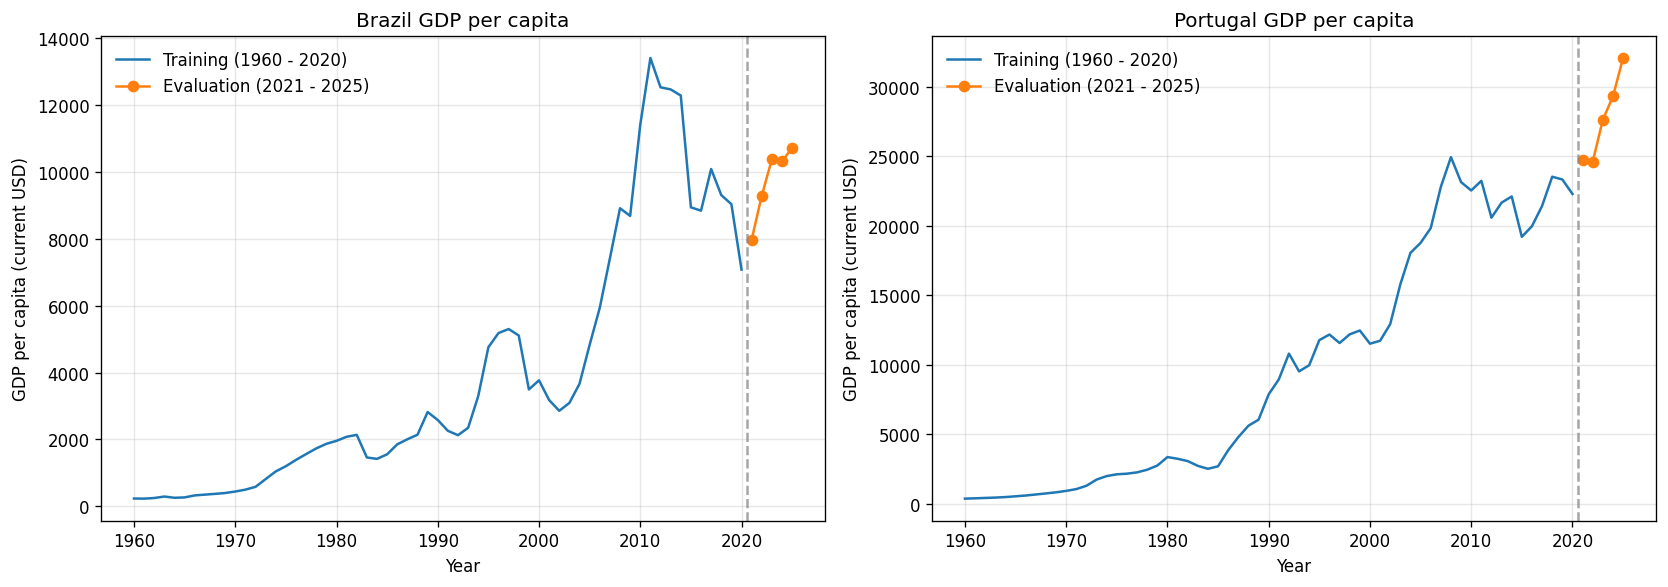

In [41]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), dpi=120)

for ax, (country, country_df) in zip(axes, COUNTRY_DATA.items()):
    train_mask = country_df["year"].between(TRAIN_START_YEAR, TRAIN_END_YEAR)
    evaluation_mask = country_df["year"].between(
        EVALUATION_START_YEAR, EVALUATION_END_YEAR
    )
    ax.plot(
        country_df.loc[train_mask, "year"],
        country_df.loc[train_mask, "gdp_per_capita"],
        label="Training (1960 - 2020)",
        color="#1f77b4",
    )
    ax.plot(
        country_df.loc[evaluation_mask, "year"],
        country_df.loc[evaluation_mask, "gdp_per_capita"],
        label="Evaluation (2021 - 2025)",
        color="#ff7f0e",
        marker="o",
    )
    ax.axvline(TRAIN_END_YEAR + 0.5, color="gray", linestyle="--", alpha=0.7)
    ax.set_title(f"{country} GDP per capita")
    ax.set_xlabel("Year")
    ax.set_ylabel("GDP per capita (current USD)")
    ax.grid(True, alpha=0.3)
    ax.legend(frameon=False)

fig.tight_layout()
save_path = ROOT / "outputs_results/03_linear_regression_timeseries_forecast/gdp_train_eval.png"
save_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(save_path, bbox_inches="tight", facecolor="white")
plt.show()


# 7. Time-series workflow: Step 3 - Define a model (specify)

Specify one simple linear regression model per country. The only predictor is calendar year.


In [36]:
from sklearn.linear_model import LinearRegression

model_specs = {
    country: LinearRegression()
    for country in COUNTRY_DATA
}


# 8. Time-series workflow: Step 4 - Train the model (estimate)

Estimate each model using observations from 1960 through 2020.


In [37]:
models = {}
training_data = {}

for country, country_df in COUNTRY_DATA.items():
    train_rows = country_df["year"].between(TRAIN_START_YEAR, TRAIN_END_YEAR)
    training_data[country] = country_df.loc[train_rows].copy()
    models[country] = model_specs[country].fit(
        training_data[country][MODEL_FEATURES],
        training_data[country]["gdp_per_capita"],
    )

print("Models trained using calendar year through 2020.")


Models trained using calendar year through 2020.


# 9. Time-series workflow: Step 5 - Check model performance (evaluate)

Predict 2021-2025 directly from the known calendar years, then compare with the observed values using regression metrics.


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

evaluation_years = np.arange(EVALUATION_START_YEAR, EVALUATION_END_YEAR + 1)
evaluation_predictions = {}
metric_rows = []

for country, model in models.items():
    actual = COUNTRY_DATA[country].loc[
        COUNTRY_DATA[country]["year"].between(
            EVALUATION_START_YEAR, EVALUATION_END_YEAR
        )
    ].sort_values("year")
    if not np.array_equal(actual["year"].to_numpy(), evaluation_years):
        raise ValueError(f"{country} must have observations for every year 2021-2025.")

    predicted_values = model.predict(actual[MODEL_FEATURES])
    predictions = actual[["year"]].copy()
    predictions["actual_gdp_per_capita"] = actual["gdp_per_capita"].to_numpy()
    predictions["predicted_gdp_per_capita"] = predicted_values
    evaluation_predictions[country] = predictions

    y_true = predictions["actual_gdp_per_capita"]
    y_pred = predictions["predicted_gdp_per_capita"]
    metric_rows.append({
        "country": country,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    })

evaluation_metrics = pd.DataFrame(metric_rows)
print(evaluation_metrics.to_string(index=False, float_format=lambda value: f"{value:,.3f}"))


 country       MAE      RMSE     R2
  Brazil   607.499   813.479  0.340
Portugal 2,890.837 3,642.175 -0.647


# 10. Time-series workflow: Step 6 - Produce forecasts (forecast)

Refit using all observations through 2025, then predict future GDP per capita from future calendar years only.


 country  year  predicted_gdp_per_capita
  Brazil  2026                 10,483.85
  Brazil  2027                 10,667.31
  Brazil  2028                 10,850.78
Portugal  2026                 27,015.66
Portugal  2027                 27,492.95
Portugal  2028                 27,970.24


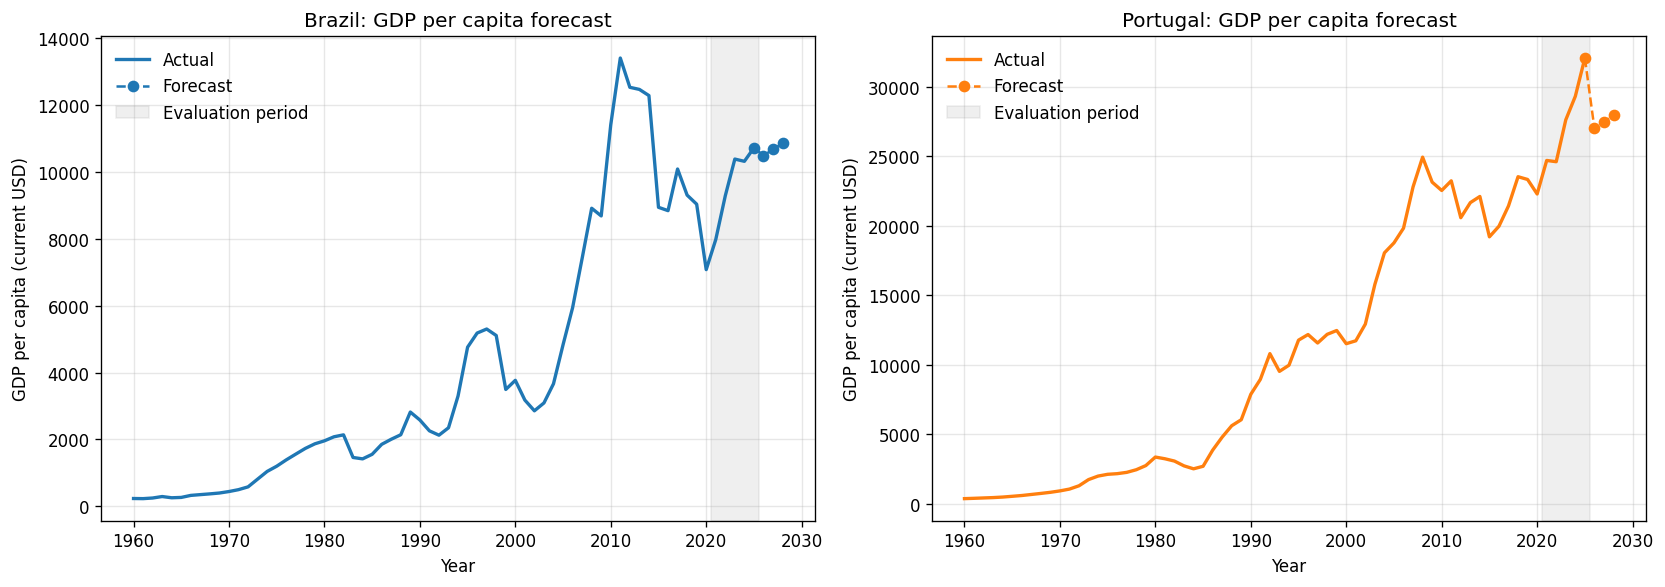

In [39]:
FORECAST_YEARS = np.arange(EVALUATION_END_YEAR + 1, EVALUATION_END_YEAR + 4)
final_models = {}
future_predictions = {}

for country, country_df in COUNTRY_DATA.items():
    final_train = country_df[
        country_df["year"].between(TRAIN_START_YEAR, EVALUATION_END_YEAR)
    ]
    final_models[country] = LinearRegression().fit(
        final_train[MODEL_FEATURES],
        final_train["gdp_per_capita"],
    )
    future_predictions[country] = pd.DataFrame({
        "year": FORECAST_YEARS,
        "predicted_gdp_per_capita": final_models[country].predict(
            pd.DataFrame({"year": FORECAST_YEARS})
        ),
    })

forecast_table = pd.concat(
    [predictions.assign(country=country)
     for country, predictions in future_predictions.items()],
    ignore_index=True,
)[["country", "year", "predicted_gdp_per_capita"]]
print(forecast_table.to_string(index=False, float_format=lambda value: f"{value:,.2f}"))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), dpi=120)
colors = {"Brazil": "#1f77b4", "Portugal": "#ff7f0e"}

for ax, (country, predictions) in zip(axes, future_predictions.items()):
    history = COUNTRY_DATA[country].loc[
        COUNTRY_DATA[country]["year"] <= EVALUATION_END_YEAR
    ]
    color = colors[country]
    ax.plot(
        history["year"],
        history["gdp_per_capita"],
        color=color,
        linewidth=2,
        label="Actual",
    )
    forecast_x = np.concatenate([[history["year"].iloc[-1]], predictions["year"]])
    forecast_y = np.concatenate([
        [history["gdp_per_capita"].iloc[-1]],
        predictions["predicted_gdp_per_capita"].to_numpy(),
    ])
    ax.plot(
        forecast_x,
        forecast_y,
        color=color,
        linestyle="--",
        marker="o",
        label="Forecast",
    )
    ax.axvspan(
        EVALUATION_START_YEAR - 0.5,
        EVALUATION_END_YEAR + 0.5,
        color="gray",
        alpha=0.12,
        label="Evaluation period",
    )
    ax.set_title(f"{country}: GDP per capita forecast")
    ax.set_xlabel("Year")
    ax.set_ylabel("GDP per capita (current USD)")
    ax.grid(True, alpha=0.3)
    ax.legend(frameon=False)

fig.tight_layout()
save_path = ROOT / "outputs_results/03_linear_regression_timeseries_forecast/gdp_forecast.png"
save_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(save_path, bbox_inches="tight", facecolor="white")
plt.show()


## Questions for discussion

1. **Improving the model:** How could we improve forecast accuracy? Should we keep the year-only straight-line trend, test a transformed trend, or consider additional economic predictors? How should we compare these options fairly?
2. **Choosing the time split:** Does training on 1960-2020 and evaluating on 2021-2025 match our forecasting goal? How should we choose the training-window length and evaluation horizon, and would rolling-origin backtesting provide a more reliable assessment?
3. **Linear versus nonlinear models:** Is a linear trend still a useful baseline for economic time series with potentially nonlinear dynamics? What evidence should guide a decision to keep it or move to a more flexible model?
